## ZOMATO EDA PROJECT

#### INSTALLING LIBRARIES

In [3]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


#### IMPORTING LIBRARIES

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

#### LOADING DATASET....

In [9]:
df = pd.read_csv(r"c:\Users\saroj\OneDrive\Desktop\Py EDA\Python EDA Project\zomato_data.csv")

#### Note:--> As now i have finish my Installing to Importing libraries and lodaing the dataset.

#### Project Starts

In [116]:
df.head() # Display the first 5 rows of the DataFrame

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [115]:
df.info() # Display information about the DataFrame

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Restaurant Name              148 non-null    str  
 1   Online_Order                 148 non-null    str  
 2   Book_Table                   148 non-null    str  
 3   Rate                         148 non-null    str  
 4   Votes                        148 non-null    int64
 5   Approx_Cost(For Two People)  148 non-null    int64
 6   Listed_In(Type)              148 non-null    str  
dtypes: int64(2), str(5)
memory usage: 8.2 KB


#### The rate table Dtype its showing str(string) insted int(integer).  
#### solving>>>> 

In [ ]:
def handleRate(value): # Define a function to handle the rate values
    value = str(value).split('/') # Split the value by '/' and take the first part
    value = value[0] 
    return float(value)# Convert the value to float and return it
df['Rate'] = df['Rate'].apply(handleRate) # Apply the handleRate function to the 'Rate' column
print(df.head(5)) 

         Restaurant Name Online_Order Book_Table  Rate  Votes  \
0                  Jalsa          Yes        Yes   4.1    775   
1         Spice Elephant          Yes         No   4.1    787   
2        San Churro Cafe          Yes         No   3.8    918   
3  Addhuri Udupi Bhojana           No         No   3.7     88   
4          Grand Village           No         No   3.8    166   

   Approx_Cost(For Two People) Listed_In(Type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  


In [ ]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Restaurant Name              148 non-null    str  
 1   Online_Order                 148 non-null    str  
 2   Book_Table                   148 non-null    str  
 3   Rate                         148 non-null    str  
 4   Votes                        148 non-null    int64
 5   Approx_Cost(For Two People)  148 non-null    int64
 6   Listed_In(Type)              148 non-null    str  
dtypes: int64(2), str(5)
memory usage: 8.2 KB


#### Checking missing or Duplicate values.

In [8]:
print(df.isnull().sum())  ## Using this for null value in each column.
print("Duplicate Rows:", df.duplicated().sum())  ## Using this for duplicate rows in the dataset.

Restaurant Name                0
Online_Order                   0
Book_Table                     0
Rate                           0
Votes                          0
Approx_Cost(For Two People)    0
Listed_In(Type)                0
dtype: int64
Duplicate Rows: 0


#### As now i have check the complete Dataset for finding any null values or duplicate vales.
#### Also I have corrected Data types in sring insted of integer.

## Questions for this data set i have think this question by seeing the dataset and solving this. 

#### Q1. How many customers votes has each resturant recived ?

In [9]:
## Answer
grouped_data = df.groupby('Listed_In(Type)')['Votes'].sum()
grouped_data  ## Grouping the data by 'listed_in(type)' and summing the 'votes' for each group.

Listed_In(Type)
Buffet     3028
Cafes      6434
Dining    20363
other      9367
Name: Votes, dtype: int64

#### Q2. How many restrurants offer table booking ?

In [10]:
## Answer
result = df['Book_Table'].value_counts()
result  ## Counting the number of restaurants that offer table booking and those that do not.

Book_Table
No     140
Yes      8
Name: count, dtype: int64

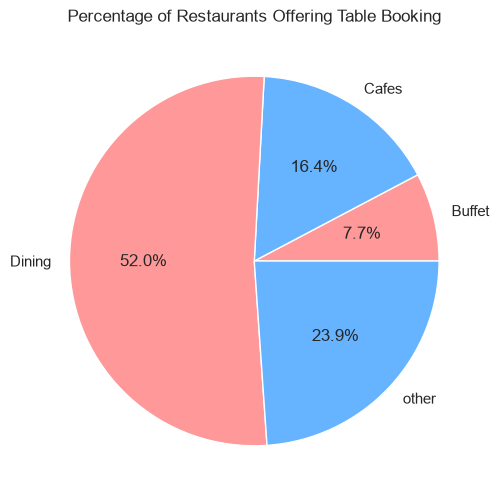

In [ ]:
plt.figure(figsize=(14, 6))  # Make the chart wider  # Autopct is used to display the percentage on the pie chart. The colors are set for better visualization.
result.plot.pie(autopct='%1.1f%%', colors=['#ff9999','#66b3ff']) # %1.1f%% formats the percentage to one decimal place, and colors are set for better visualization.   
plt.title('Percentage of Restaurants Offering Table Booking') # Set the title of the chart
plt.show()

#### Q3. Which five resturants have highest number of votes ?

In [ ]:
## Answer
top5 =df.nlargest(5, 'Votes')[['Restaurant Name', 'Votes']] # Select the top 5 restaurants with the highest number of votes
print(top5)  ## Finding the top 5 restaurants with the highest number of votes. 

      Restaurant Name  Votes
38  Empire Restaurant   4884
86      Meghana Foods   4401
7              Onesta   2556
44             Onesta   2556
65        Kabab Magic   1720


<Figure size 1400x1400 with 0 Axes>

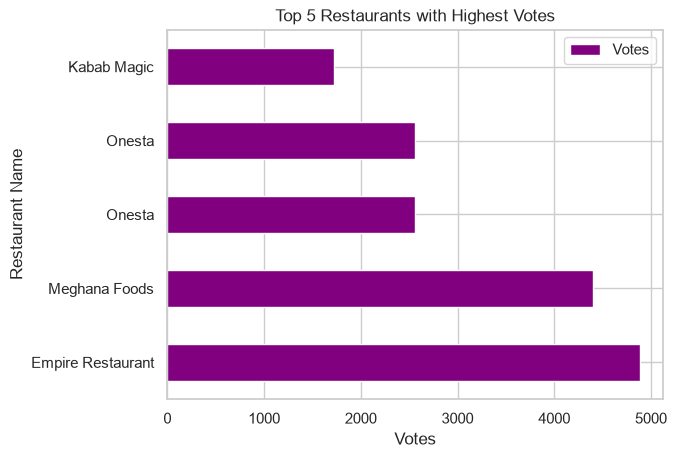

In [ ]:
plt.figure(figsize=(14, 14))  # Make the chart wider
top5.plot.barh(x='Restaurant Name', y='Votes', color='purple') # Plot the horizontal bar chart
plt.title('Top 5 Restaurants with Highest Votes') # Set the title of the chart
plt.xlabel('Votes') # Set the label for the x-axis
plt.ylabel('Restaurant Name') # Set the label for the y-axis
plt.show() # Display the chart

#### Q4.Is there relationship between resturant ratings and customers votes ?

In [20]:
## Answer
df.head()

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


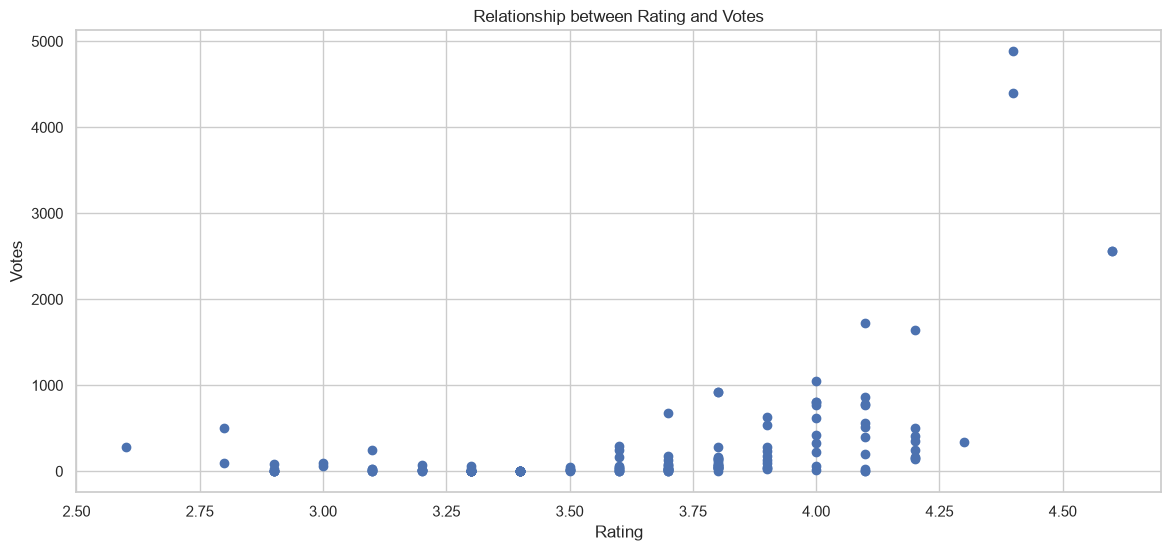

In [ ]:
plt.figure(figsize=(14, 6))  # Make the chart wider
rating = pd.to_numeric( # Convert the 'Rate' column to numeric, handling errors
    df['Rate'].astype(str).str.split('/').str[0],# Extract the first part before the '/'
    errors='coerce'# Handle errors by converting them to NaN
)
plt.scatter(rating, df['Votes']) # Create a scatter plot
plt.xlabel('Rating') # Set the label for the x-axis
plt.ylabel('Votes') # Set the label for the y-axis
plt.title('Relationship between Rating and Votes') # Set the title of the chart
plt.show() # Display the charts

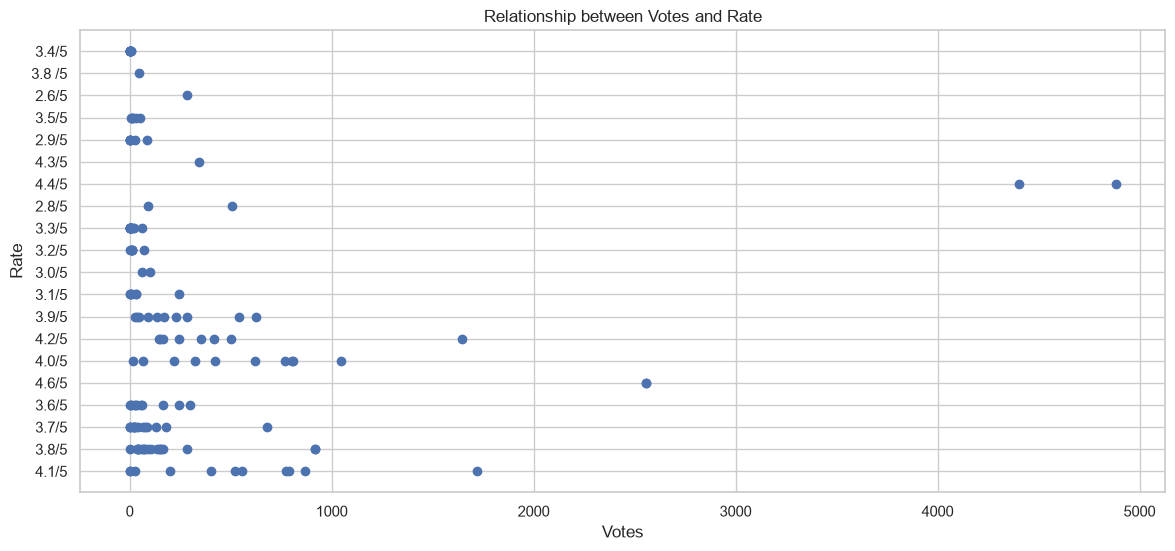

In [117]:
plt.figure(figsize=(14, 6))  # Make the chart wider
plt.scatter(df['Votes'], df['Rate']) # Create a scatter plot to visualize the relationship between 'Votes' and 'Rate'
plt.xlabel('Votes') # Set the label for the x-axis
plt.ylabel('Rate') # Set the label for the y-axis
plt.title('Relationship between Votes and Rate') # Set the title of the chart
plt.show()

#### Q5. What is average rating for each resturant type?


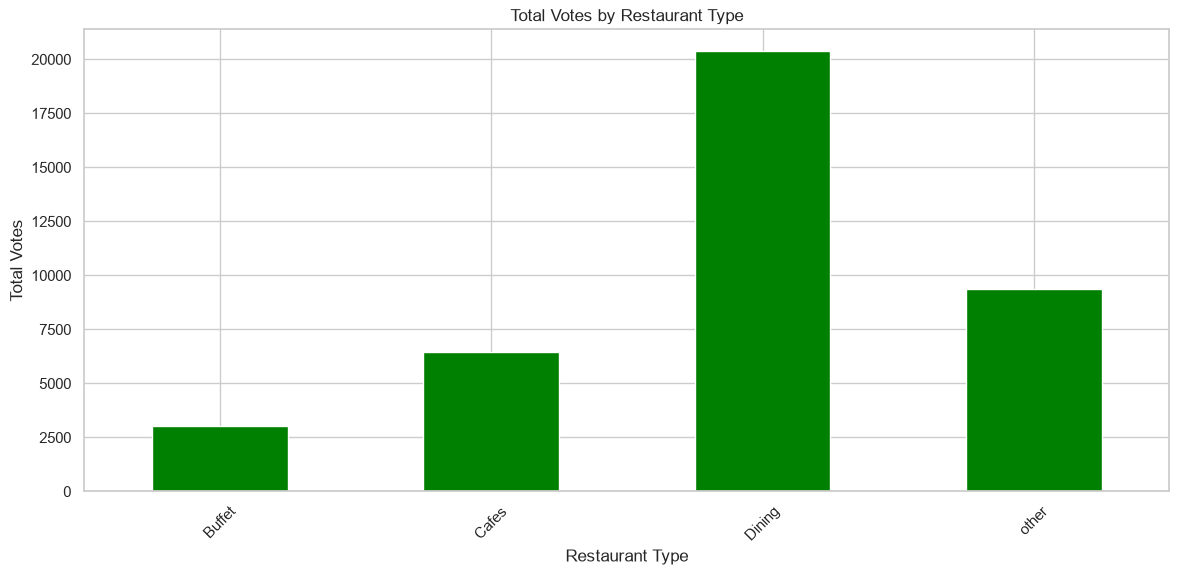

Listed_In(Type)
Dining    20363
other      9367
Cafes      6434
Buffet     3028
Name: Votes, dtype: int64


In [118]:
## Answer
plt.figure(figsize=(14, 6))  # Make the chart wider
result = df.groupby('Listed_In(Type)')['Votes'].sum() # Group the data by 'Listed_In(Type)' and sum the 'Votes' for each group
result.plot(kind='bar', color='Green') # Plot the bar chart
plt.title('Total Votes by Restaurant Type') # Set the title of the chart
plt.xlabel('Restaurant Type') # Set the label for the x-axis
plt.ylabel('Total Votes') # Set the label for the y-axis
plt.xticks(rotation=45) # Rotate the x-axis labels by 45 degrees
plt.show() # Display the chart
print(result.sort_values(ascending=False))  ## Sorting the result in descending order to see
## which restaurant type has the highest total votes.


#### Q6. What type of resturant do the most majority of customers order form ?

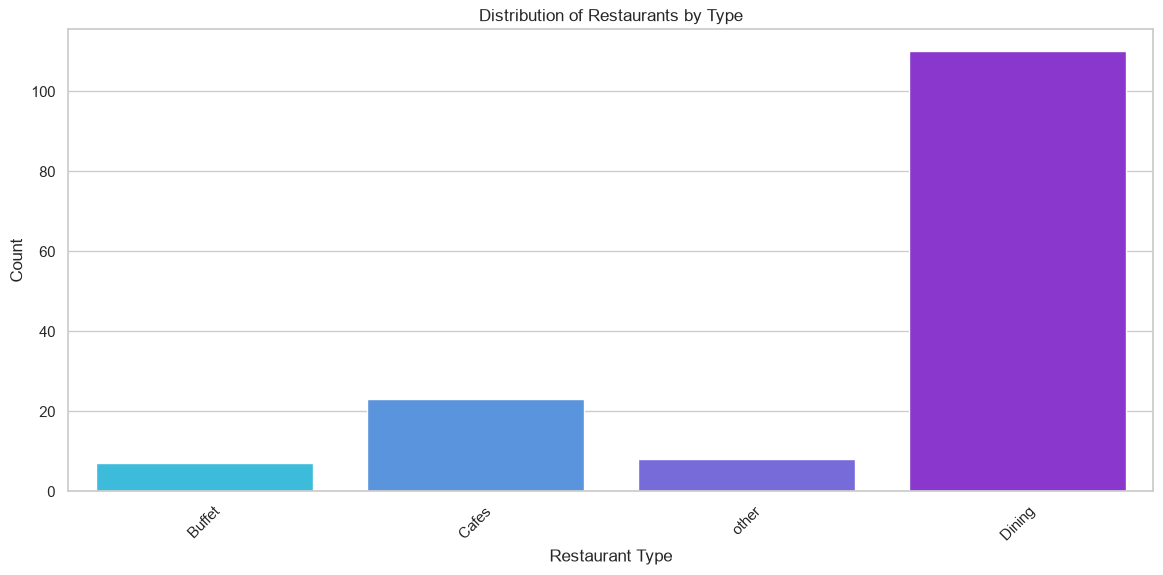

In [ ]:
## Answer
plt.figure(figsize=(14, 6))  # Make the chart wider
sns.countplot(
    x=df['Listed_In(Type)'],# Set the x-axis to the 'Listed_In(Type)' column
    hue=df['Listed_In(Type)'], # Set the hue to the 'Listed_In(Type)' column for color differentiation
    palette=["#21cbf6", "#4592f1", "#6958ec", "#8c1ee6"],
    legend=False # Hide the legend
)
plt.title('Distribution of Restaurants by Type') # Set the title of the chart
plt.xlabel('Restaurant Type') # Set the label for the x-axis
plt.ylabel('Count') # Set the label for the y-axis
plt.xticks(rotation=45) # Rotate the x-axis labels by 45 degrees
plt.show() # Display the charts

#### Q7. What ratings do resturant most commonly recive ?

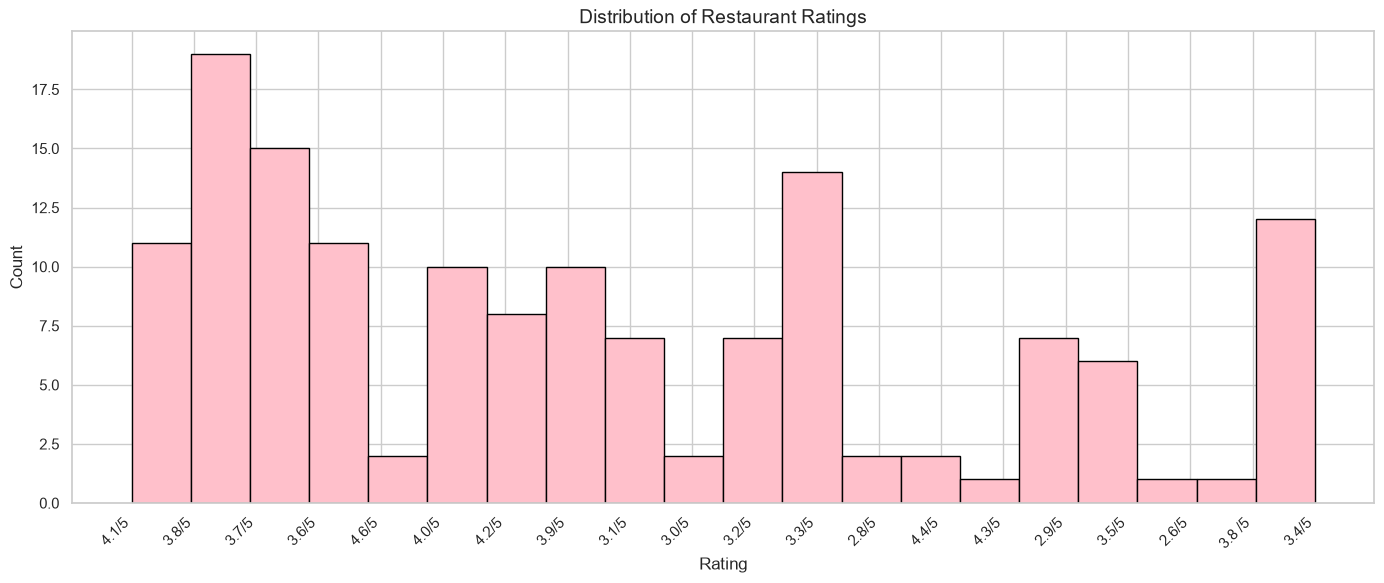

In [75]:
## Answer
plt.figure(figsize=(14, 6))  # Make the chart wider
plt.hist(df['Rate'], bins=20, color='pink', edgecolor='black') # Bins set to 20 for better granularity.
plt.title('Distribution of Restaurant Ratings',fontsize=14)
plt.xlabel('Rating',fontsize=12)
plt.ylabel('Count',fontsize=12)
plt.xticks(rotation=45, ha='right')  # Slants the labels so they don't touch
plt.tight_layout()                   # Prevents rotated labels from getting cut off
plt.show()


#### Q8.Which restaurant type has the highest average cost for two people ?

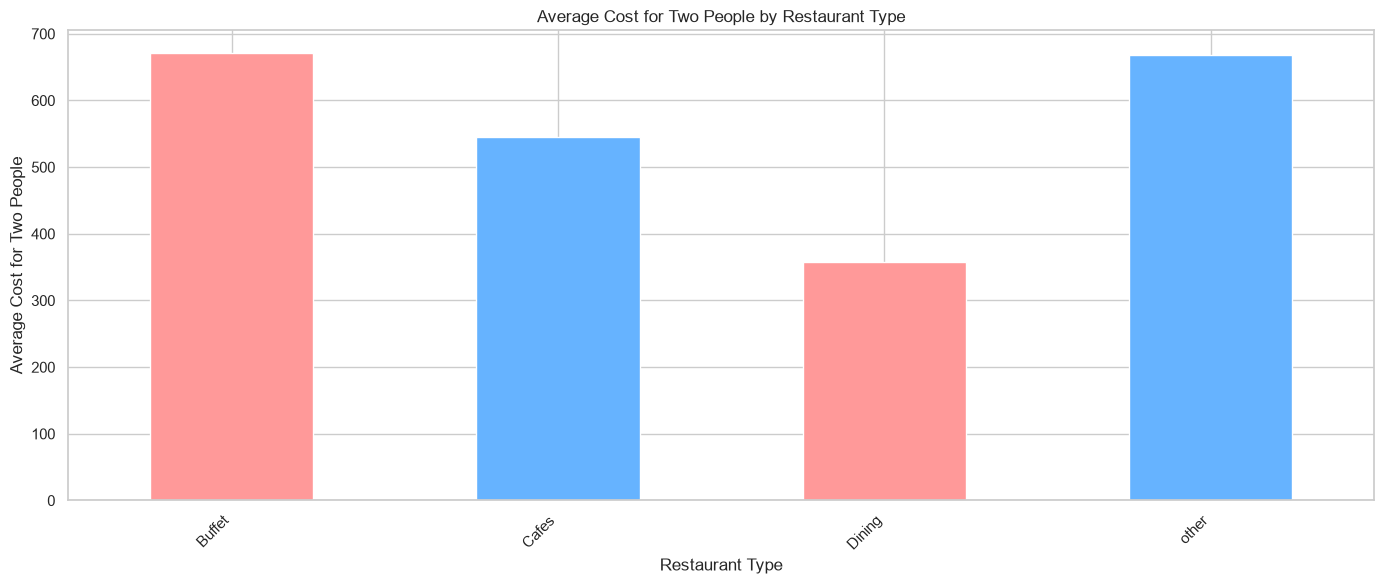

In [105]:
### Answer
plt.figure(figsize=(14, 6))  # Make the chart wider
result = df.groupby('Listed_In(Type)')['Approx_Cost(For Two People)'].mean()
result.plot(kind='bar',  figsize=(14, 6), color=['#ff9999','#66b3ff'])
plt.title('Average Cost for Two People by Restaurant Type')
plt.xlabel('Restaurant Type', fontsize=12)
plt.ylabel('Average Cost for Two People', fontsize=12)
plt.xticks(rotation=45, ha='right')  # Slants the labels so they don't touch
plt.tight_layout()                   # Prevents rotated labels from getting cut off
plt.show()

#### Q9. Which order mode--Online or Offline--gets better rating ?

In [92]:
### Answer
df.head()

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


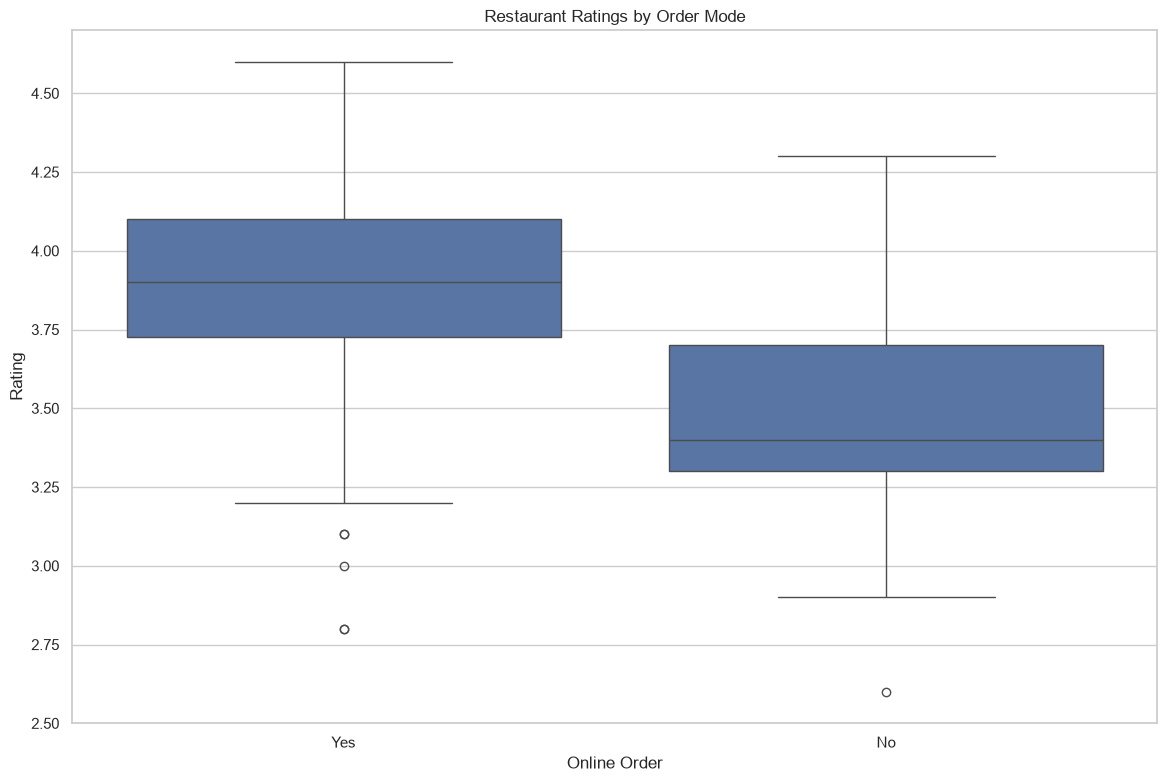

In [ ]:
plt.figure(figsize=(14, 9))  # Make the chart wider
sns.set(style="whitegrid")
plot_df = df.assign(RateNumeric=pd.to_numeric( # Convert the 'Rate' column to numeric, handling errors
    df['Rate'].astype(str).str.split('/').str[0],
    errors='coerce'# Handle errors by converting them to NaN
))

sns.boxplot(x='Online_Order', y='RateNumeric', data=plot_df)# Create a box plot to visualize the distribution of ratings based on online order availability
plt.title('Restaurant Ratings by Order Mode')# Set the title of the chart
plt.xlabel('Online Order')# Set the label for the x-axis
plt.ylabel('Rating')# Set the label for the y-axis
plt.show()


#### Q10. Which restaurant types have more offline-ordering records ?


In [ ]:
pivot_table = df.pivot_table( # Create a pivot table
    index='Listed_In(Type)', # Set the index to the 'Listed_In(Type)' column
    columns='Online_Order', 
    values='Votes', 
    aggfunc='size',
    fill_value=0)
print(pivot_table)  ## Creating a pivot table to see the distribution of votes based on restaurant type and online order availability.

Online_Order     No  Yes
Listed_In(Type)         
Buffet            3    4
Cafes             8   15
Dining           77   33
other             2    6


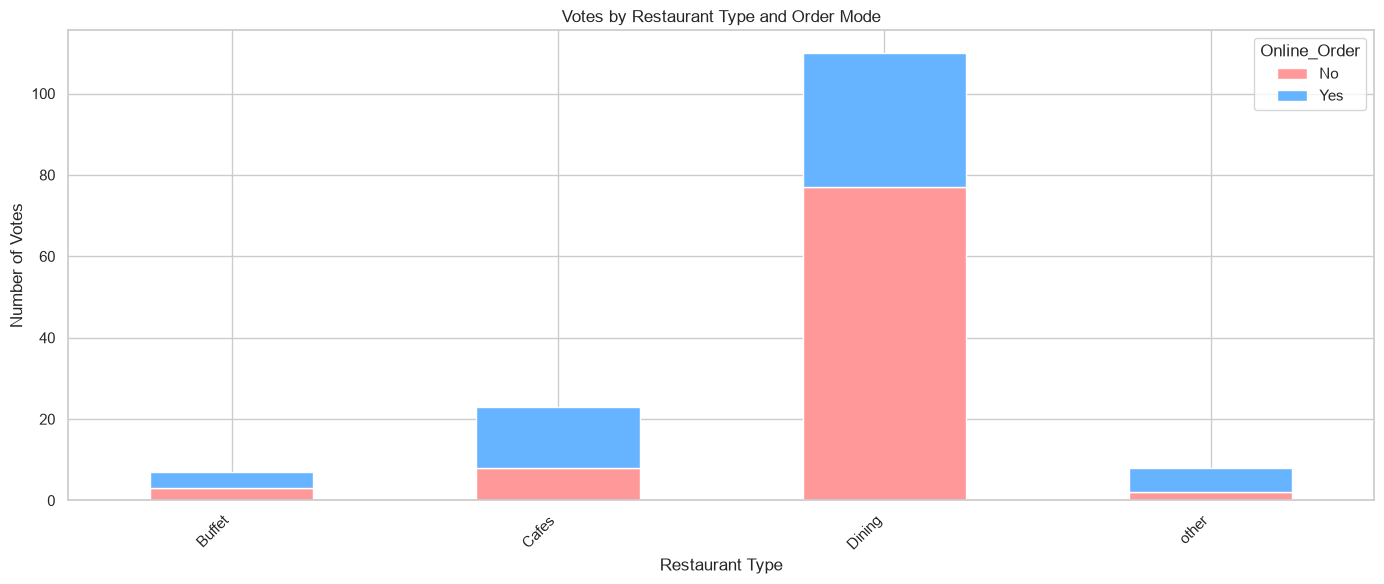

In [104]:
## Answer
pivot_table = df.pivot_table(
    index='Listed_In(Type)', 
    columns='Online_Order', 
    values='Votes', 
    aggfunc='size',
    fill_value=0
)
pivot_table.plot(kind='bar', stacked=True, figsize=(14, 6), color=['#ff9999','#66b3ff'])
plt.title('Votes by Restaurant Type and Order Mode')
plt.xlabel('Restaurant Type')
plt.ylabel('Number of Votes')
plt.xticks(rotation=45, ha='right')  # Slants the labels so they don't touch
plt.tight_layout()                   # Prevents rotated labels from getting cut off
plt.show()

# OR WE CAN ALSO UNDERSTAND BETTER WITH HEATMAP

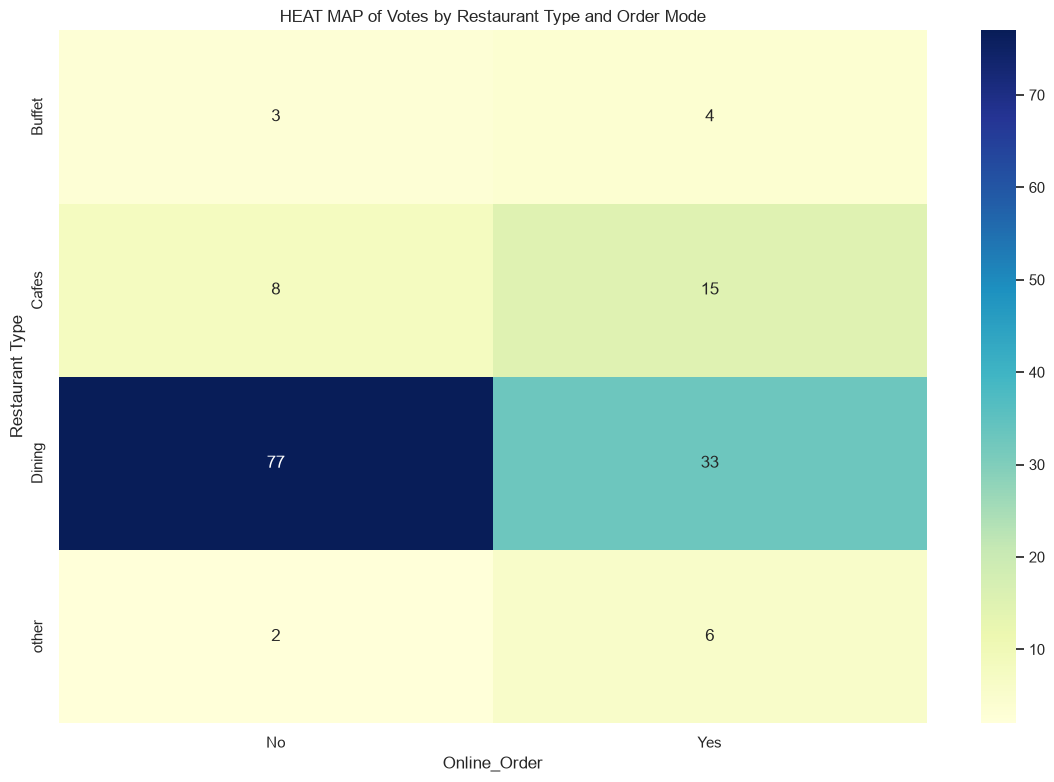

In [119]:
plt.figure(figsize=(14, 9))  # Make the chart wider
sns.heatmap(pivot_table, annot=True, fmt='d', cmap='YlGnBu') ## yl=Yellow,Gn=Green,Bu=Blue
plt.title('HEAT MAP of Votes by Restaurant Type and Order Mode')
plt.ylabel('Restaurant Type')
plt.show()